In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Assignment Cohort Data - Fintech Data.xlsx to Assignment Cohort Data - Fintech Data.xlsx


In [ ]:
import pandas as pd

df_cohort = pd.read_excel(
    "Assignment Cohort Data - Fintech Data.xlsx"
)

df_cohort.head()

,date,username,revenue
0,2024-03-14,GammaRay3,12046319.0
1,2024-12-17,OpalsOn,0.0
2,2024-12-17,QuietQuail,7700.0
3,2024-09-22,RoomRat,122127392.0
4,2024-11-04,LazyLizard,23411397.0


In [ ]:
df_cohort.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22466 entries, 0 to 22465
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      22466 non-null  datetime64[ns]
 1   username  22466 non-null  object        
 2   revenue   22466 non-null  float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 526.7+ KB


In [ ]:
df_cohort.shape

(22466, 3)

In [ ]:
df_cohort.isnull().sum()

,0
date,0
username,0
revenue,0


In [ ]:
df_cohort.columns

Index(['date', 'username', 'revenue'], dtype='object')

In [ ]:
df_cohort["date"] = pd.to_datetime(df_cohort["date"])

df_cohort["date"].min(), df_cohort["date"].max()

(Timestamp('2024-01-01 00:00:00'), Timestamp('2024-12-31 00:00:00'))

In [ ]:
df_cohort.head(10)

,date,username,revenue
0,2024-03-14,GammaRay3,12046319.0
1,2024-12-17,OpalsOn,0.0
2,2024-12-17,QuietQuail,7700.0
3,2024-09-22,RoomRat,122127392.0
4,2024-11-04,LazyLizard,23411397.0
5,2024-12-11,EarlyEagle,69375.0
6,2024-08-23,DeltaForce4,612751.0
7,2024-07-01,CoolCrab,63000.0
8,2024-10-30,RoomRat,99967198.0
9,2024-05-28,SteelStay,0.0


In [ ]:
df_cohort["transaction_month"] = (
    df_cohort["date"].dt.to_period("M")
)

In [ ]:
df_cohort["cohort_month"] = (
    df_cohort.groupby("username")["transaction_month"]
    .transform("min")
)

In [ ]:
df_cohort[
    ["date", "username", "transaction_month", "cohort_month", "revenue"]
].head(20)

,date,username,transaction_month,cohort_month,revenue
0,2024-03-14,GammaRay3,2024-03,2024-01,12046319.0
1,2024-12-17,OpalsOn,2024-12,2024-01,0.0
2,2024-12-17,QuietQuail,2024-12,2024-01,7700.0
3,2024-09-22,RoomRat,2024-09,2024-09,122127392.0
4,2024-11-04,LazyLizard,2024-11,2024-10,23411397.0
5,2024-12-11,EarlyEagle,2024-12,2024-09,69375.0
6,2024-08-23,DeltaForce4,2024-08,2024-01,612751.0
7,2024-07-01,CoolCrab,2024-07,2024-01,63000.0
8,2024-10-30,RoomRat,2024-10,2024-09,99967198.0
9,2024-05-28,SteelStay,2024-05,2024-01,0.0


In [ ]:
df_cohort["cohort_index"] = (
    (df_cohort["transaction_month"].dt.year -
     df_cohort["cohort_month"].dt.year) * 12
    +
    (df_cohort["transaction_month"].dt.month -
     df_cohort["cohort_month"].dt.month)
)

In [ ]:
cohort_data = (
    df_cohort
    .groupby(["cohort_month", "cohort_index"])["username"]
    .nunique()
    .reset_index()
)

In [ ]:
cohort_table = cohort_data.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="username"
)

In [ ]:
cohort_table

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2024-01,115.0,91.0,85.0,85.0,83.0,80.0,76.0,72.0,71.0,65.0,58.0,68.0
2024-02,15.0,4.0,5.0,5.0,3.0,4.0,3.0,1.0,2.0,2.0,4.0,NaN
2024-03,7.0,5.0,3.0,3.0,3.0,3.0,4.0,5.0,3.0,6.0,NaN,NaN
2024-04,8.0,3.0,6.0,5.0,5.0,6.0,5.0,6.0,5.0,NaN,NaN,NaN
2024-05,9.0,6.0,6.0,7.0,6.0,7.0,4.0,5.0,NaN,NaN,NaN,NaN
2024-06,6.0,5.0,5.0,4.0,3.0,3.0,2.0,NaN,NaN,NaN,NaN,NaN
2024-07,10.0,9.0,9.0,9.0,9.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN
2024-08,12.0,7.0,9.0,8.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09,13.0,10.0,8.0,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
retention_table = cohort_table.divide(
    cohort_table[0],
    axis=0
) * 100

In [ ]:
retention_table.round(2)

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2024-01,100.0,79.13,73.91,73.91,72.17,69.57,66.09,62.61,61.74,56.52,50.43,59.13
2024-02,100.0,26.67,33.33,33.33,20.00,26.67,20.00,6.67,13.33,13.33,26.67,NaN
2024-03,100.0,71.43,42.86,42.86,42.86,42.86,57.14,71.43,42.86,85.71,NaN,NaN
2024-04,100.0,37.50,75.00,62.50,62.50,75.00,62.50,75.00,62.50,NaN,NaN,NaN
2024-05,100.0,66.67,66.67,77.78,66.67,77.78,44.44,55.56,NaN,NaN,NaN,NaN
2024-06,100.0,83.33,83.33,66.67,50.00,50.00,33.33,NaN,NaN,NaN,NaN,NaN
2024-07,100.0,90.00,90.00,90.00,90.00,90.00,NaN,NaN,NaN,NaN,NaN,NaN
2024-08,100.0,58.33,75.00,66.67,75.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09,100.0,76.92,61.54,76.92,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df_cohort["date"] = pd.to_datetime(df_cohort["date"])

df_cohort["transaction_month"] = (
    df_cohort["date"].dt.to_period("M")
)

df_cohort["cohort_month"] = (
    df_cohort.groupby("username")["transaction_month"]
    .transform("min")
)

df_cohort["cohort_index"] = (
    (df_cohort["transaction_month"].dt.year -
     df_cohort["cohort_month"].dt.year) * 12
    +
    (df_cohort["transaction_month"].dt.month -
     df_cohort["cohort_month"].dt.month)
)

df_cohort[
    ["date", "username", "transaction_month",
     "cohort_month", "cohort_index", "revenue"]
].head(20)

,date,username,transaction_month,cohort_month,cohort_index,revenue
0,2024-03-14,GammaRay3,2024-03,2024-01,2,12046319.0
1,2024-12-17,OpalsOn,2024-12,2024-01,11,0.0
2,2024-12-17,QuietQuail,2024-12,2024-01,11,7700.0
3,2024-09-22,RoomRat,2024-09,2024-09,0,122127392.0
4,2024-11-04,LazyLizard,2024-11,2024-10,1,23411397.0
5,2024-12-11,EarlyEagle,2024-12,2024-09,3,69375.0
6,2024-08-23,DeltaForce4,2024-08,2024-01,7,612751.0
7,2024-07-01,CoolCrab,2024-07,2024-01,6,63000.0
8,2024-10-30,RoomRat,2024-10,2024-09,1,99967198.0
9,2024-05-28,SteelStay,2024-05,2024-01,4,0.0


In [ ]:
cohort_data = (
    df_cohort
    .groupby(["cohort_month", "cohort_index"])["username"]
    .nunique()
    .reset_index()
)

cohort_data.head(10)

,cohort_month,cohort_index,username
0,2024-01,0,115
1,2024-01,1,91
2,2024-01,2,85
3,2024-01,3,85
4,2024-01,4,83
5,2024-01,5,80
6,2024-01,6,76
7,2024-01,7,72
8,2024-01,8,71
9,2024-01,9,65


In [ ]:
cohort_table = cohort_data.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="username"
)

cohort_table

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2024-01,115.0,91.0,85.0,85.0,83.0,80.0,76.0,72.0,71.0,65.0,58.0,68.0
2024-02,15.0,4.0,5.0,5.0,3.0,4.0,3.0,1.0,2.0,2.0,4.0,NaN
2024-03,7.0,5.0,3.0,3.0,3.0,3.0,4.0,5.0,3.0,6.0,NaN,NaN
2024-04,8.0,3.0,6.0,5.0,5.0,6.0,5.0,6.0,5.0,NaN,NaN,NaN
2024-05,9.0,6.0,6.0,7.0,6.0,7.0,4.0,5.0,NaN,NaN,NaN,NaN
2024-06,6.0,5.0,5.0,4.0,3.0,3.0,2.0,NaN,NaN,NaN,NaN,NaN
2024-07,10.0,9.0,9.0,9.0,9.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN
2024-08,12.0,7.0,9.0,8.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09,13.0,10.0,8.0,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
retention_table = cohort_table.divide(
    cohort_table[0],
    axis=0
) * 100

retention_table = retention_table.round(2)

retention_table

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2024-01,100.0,79.13,73.91,73.91,72.17,69.57,66.09,62.61,61.74,56.52,50.43,59.13
2024-02,100.0,26.67,33.33,33.33,20.00,26.67,20.00,6.67,13.33,13.33,26.67,NaN
2024-03,100.0,71.43,42.86,42.86,42.86,42.86,57.14,71.43,42.86,85.71,NaN,NaN
2024-04,100.0,37.50,75.00,62.50,62.50,75.00,62.50,75.00,62.50,NaN,NaN,NaN
2024-05,100.0,66.67,66.67,77.78,66.67,77.78,44.44,55.56,NaN,NaN,NaN,NaN
2024-06,100.0,83.33,83.33,66.67,50.00,50.00,33.33,NaN,NaN,NaN,NaN,NaN
2024-07,100.0,90.00,90.00,90.00,90.00,90.00,NaN,NaN,NaN,NaN,NaN,NaN
2024-08,100.0,58.33,75.00,66.67,75.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09,100.0,76.92,61.54,76.92,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


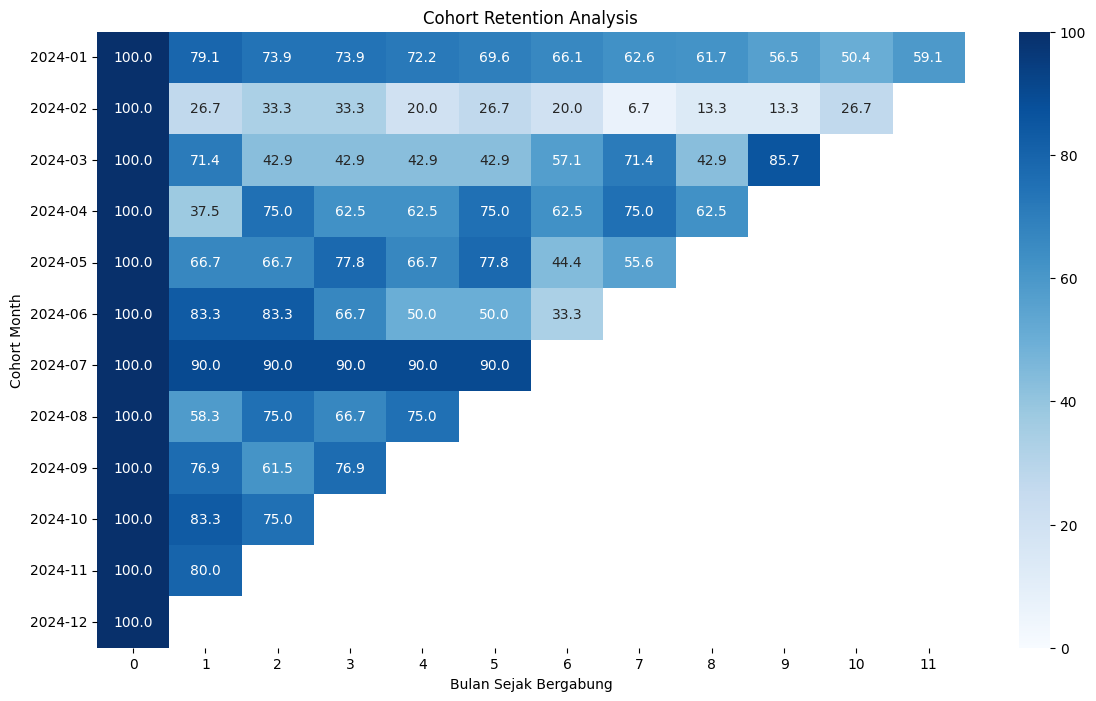

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 8))

sns.heatmap(
    retention_table,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100
)

plt.title("Cohort Retention Analysis")
plt.xlabel("Bulan Sejak Bergabung")
plt.ylabel("Cohort Month")
plt.show()

In [ ]:
retention_table

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2024-01,100.0,79.13,73.91,73.91,72.17,69.57,66.09,62.61,61.74,56.52,50.43,59.13
2024-02,100.0,26.67,33.33,33.33,20.00,26.67,20.00,6.67,13.33,13.33,26.67,NaN
2024-03,100.0,71.43,42.86,42.86,42.86,42.86,57.14,71.43,42.86,85.71,NaN,NaN
2024-04,100.0,37.50,75.00,62.50,62.50,75.00,62.50,75.00,62.50,NaN,NaN,NaN
2024-05,100.0,66.67,66.67,77.78,66.67,77.78,44.44,55.56,NaN,NaN,NaN,NaN
2024-06,100.0,83.33,83.33,66.67,50.00,50.00,33.33,NaN,NaN,NaN,NaN,NaN
2024-07,100.0,90.00,90.00,90.00,90.00,90.00,NaN,NaN,NaN,NaN,NaN,NaN
2024-08,100.0,58.33,75.00,66.67,75.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09,100.0,76.92,61.54,76.92,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
retention_month1 = retention_table[1].dropna()

retention_month1.sort_values(ascending=False)

,1
cohort_month,
2024-07,90.00
2024-06,83.33
2024-10,83.33
2024-11,80.00
2024-01,79.13
2024-09,76.92
2024-03,71.43
2024-05,66.67
2024-08,58.33


In [ ]:
average_retention = retention_table.mean(axis=1).sort_values(
    ascending=False
)

average_retention.round(2)

,0
cohort_month,
2024-12,100.00
2024-07,91.67
2024-11,90.00
2024-10,86.11
2024-09,78.84
2024-08,75.00
2024-05,69.45
2024-01,68.77
2024-04,68.06


In [ ]:
cohort_table

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2024-01,115.0,91.0,85.0,85.0,83.0,80.0,76.0,72.0,71.0,65.0,58.0,68.0
2024-02,15.0,4.0,5.0,5.0,3.0,4.0,3.0,1.0,2.0,2.0,4.0,NaN
2024-03,7.0,5.0,3.0,3.0,3.0,3.0,4.0,5.0,3.0,6.0,NaN,NaN
2024-04,8.0,3.0,6.0,5.0,5.0,6.0,5.0,6.0,5.0,NaN,NaN,NaN
2024-05,9.0,6.0,6.0,7.0,6.0,7.0,4.0,5.0,NaN,NaN,NaN,NaN
2024-06,6.0,5.0,5.0,4.0,3.0,3.0,2.0,NaN,NaN,NaN,NaN,NaN
2024-07,10.0,9.0,9.0,9.0,9.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN
2024-08,12.0,7.0,9.0,8.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09,13.0,10.0,8.0,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
retention_table

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2024-01,100.0,79.13,73.91,73.91,72.17,69.57,66.09,62.61,61.74,56.52,50.43,59.13
2024-02,100.0,26.67,33.33,33.33,20.00,26.67,20.00,6.67,13.33,13.33,26.67,NaN
2024-03,100.0,71.43,42.86,42.86,42.86,42.86,57.14,71.43,42.86,85.71,NaN,NaN
2024-04,100.0,37.50,75.00,62.50,62.50,75.00,62.50,75.00,62.50,NaN,NaN,NaN
2024-05,100.0,66.67,66.67,77.78,66.67,77.78,44.44,55.56,NaN,NaN,NaN,NaN
2024-06,100.0,83.33,83.33,66.67,50.00,50.00,33.33,NaN,NaN,NaN,NaN,NaN
2024-07,100.0,90.00,90.00,90.00,90.00,90.00,NaN,NaN,NaN,NaN,NaN,NaN
2024-08,100.0,58.33,75.00,66.67,75.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09,100.0,76.92,61.54,76.92,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
retention_table[1].dropna().sort_values(ascending=False)

,1
cohort_month,
2024-07,90.00
2024-06,83.33
2024-10,83.33
2024-11,80.00
2024-01,79.13
2024-09,76.92
2024-03,71.43
2024-05,66.67
2024-08,58.33


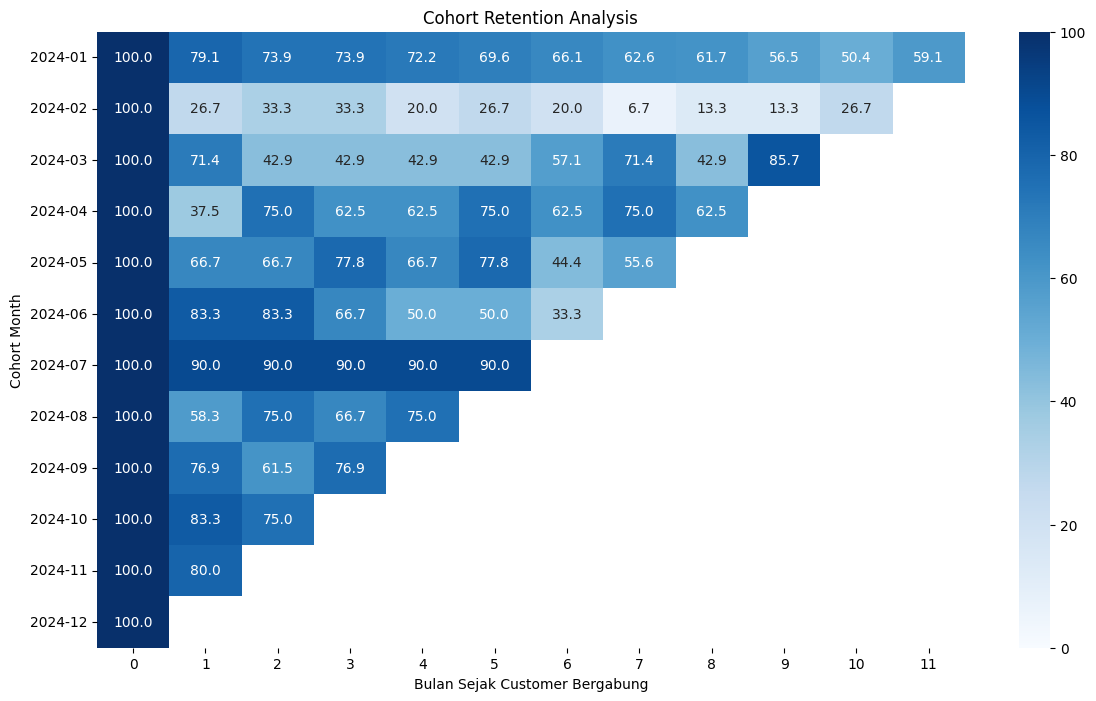

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 8))

sns.heatmap(
    retention_table,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100
)

plt.title("Cohort Retention Analysis")
plt.xlabel("Bulan Sejak Customer Bergabung")
plt.ylabel("Cohort Month")
plt.show()

In [ ]:
month_1 = (
    retention_table[1]
    .dropna()
    .sort_values(ascending=False)
)

month_1

,1
cohort_month,
2024-07,90.00
2024-06,83.33
2024-10,83.33
2024-11,80.00
2024-01,79.13
2024-09,76.92
2024-03,71.43
2024-05,66.67
2024-08,58.33


In [ ]:
print("Retention Month 1 Tertinggi:")
print(month_1.index[0], "=", month_1.iloc[0], "%")

print("\nRetention Month 1 Terendah:")
print(month_1.index[-1], "=", month_1.iloc[-1], "%")

Retention Month 1 Tertinggi:
2024-07 = 90.0 %

Retention Month 1 Terendah:
2024-02 = 26.67 %


In [ ]:
average_retention = (
    retention_table.mean(axis=1)
    .sort_values(ascending=False)
)

average_retention.round(2)

,0
cohort_month,
2024-12,100.00
2024-07,91.67
2024-11,90.00
2024-10,86.11
2024-09,78.84
2024-08,75.00
2024-05,69.45
2024-01,68.77
2024-04,68.06


In [ ]:
retention_table.to_csv(
    "cohort_retention.csv"
)

In [ ]:
from google.colab import files

files.download("cohort_retention.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>